In [1]:
import pickle
import pandas as pd

In [5]:
feature_bow = pickle.load(open("feature-bow.p", 'rb'))
model_nb = pickle.load(open("model-nb.p", 'rb'))
model_nn = pickle.load(open("model-nn.p", 'rb'))

data =  pd.read_csv("rupiah_clean.csv")

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator MLPClassifier from version 0.22.2.post1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


,full_text
0,nilai tukar rupiah hari ini kamis oktober te...
1,jujur memang capek liat berita di indonesia hi...
2,anak usaha astra international di sektor perke...
3,nilai tukar dolar amerika serikat terhadap rup...
4,nilai tukar rupiah hari ini kamis oktober me...
...,...
994,baca di sini \n\nbank indonesia bi akan mempe...
995,gue lebih percaya thomaskong beneran pacaran d...
996,informasi kurs jisdor referensi kursnilai tuka...
997,investor asing masih terus melakukan aksi jual...


In [6]:
def predict_sentiment(sent):
    # feature extraction
    text_feature = feature_bow.transform([sent])
    # predict
    return model_nb.predict(text_feature)[0]

In [7]:
data['sentiment'] = data.full_text.apply(predict_sentiment)
data

,full_text,sentiment
0,nilai tukar rupiah hari ini kamis oktober te...,neutral
1,jujur memang capek liat berita di indonesia hi...,negative
2,anak usaha astra international di sektor perke...,positive
3,nilai tukar dolar amerika serikat terhadap rup...,neutral
4,nilai tukar rupiah hari ini kamis oktober me...,neutral
...,...,...
994,baca di sini \n\nbank indonesia bi akan mempe...,neutral
995,gue lebih percaya thomaskong beneran pacaran d...,negative
996,informasi kurs jisdor referensi kursnilai tuka...,neutral
997,investor asing masih terus melakukan aksi jual...,neutral


In [8]:
data.to_csv('/content/rupiah_predicted.csv', index=False)

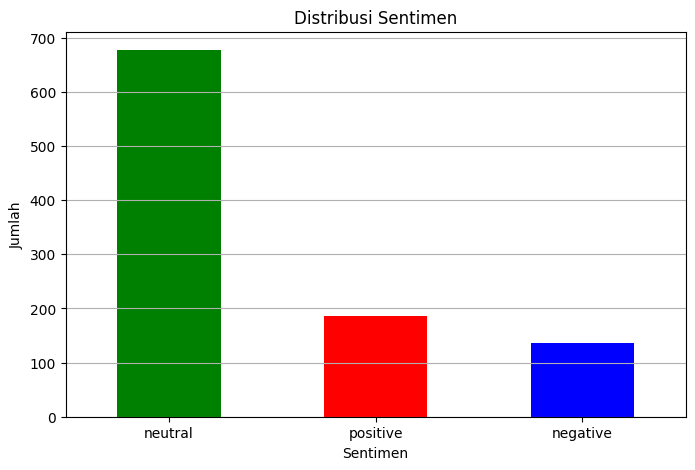

sentiment
neutral     677
positive    186
negative    136
Name: count, dtype: int64


In [9]:
import matplotlib.pyplot as plt

sentiment_counts = data['sentiment'].value_counts()

plt.figure(figsize=(8, 5))
sentiment_counts.plot(kind='bar', color=['green', 'red', 'blue'])
plt.title('Distribusi Sentimen')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

print(sentiment_counts)

In [10]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter

In [17]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords as stopwords_scratch

# panggil stopword id
list_stopwords = stopwords_scratch.words('indonesian')
print(list_stopwords)
# panggil stopword en
list_stopwords_en = stopwords_scratch.words('english')
# gabungkan id & en
list_stopwords.extend(list_stopwords_en)
# tambah daftar stopword jika perlu
list_stopwords.extend(['ya', 'yg', 'ga', 'yuk', 'dah', 'ngga', 'engga', 'ygy'])
stopwords = list_stopwords

['ada', 'adalah', 'adanya', 'adapun', 'agak', 'agaknya', 'agar', 'akan', 'akankah', 'akhir', 'akhiri', 'akhirnya', 'aku', 'akulah', 'amat', 'amatlah', 'anda', 'andalah', 'antar', 'antara', 'antaranya', 'apa', 'apaan', 'apabila', 'apakah', 'apalagi', 'apatah', 'artinya', 'asal', 'asalkan', 'atas', 'atau', 'ataukah', 'ataupun', 'awal', 'awalnya', 'bagai', 'bagaikan', 'bagaimana', 'bagaimanakah', 'bagaimanapun', 'bagi', 'bagian', 'bahkan', 'bahwa', 'bahwasanya', 'baik', 'bakal', 'bakalan', 'balik', 'banyak', 'bapak', 'baru', 'bawah', 'beberapa', 'begini', 'beginian', 'beginikah', 'beginilah', 'begitu', 'begitukah', 'begitulah', 'begitupun', 'bekerja', 'belakang', 'belakangan', 'belum', 'belumlah', 'benar', 'benarkah', 'benarlah', 'berada', 'berakhir', 'berakhirlah', 'berakhirnya', 'berapa', 'berapakah', 'berapalah', 'berapapun', 'berarti', 'berawal', 'berbagai', 'berdatangan', 'beri', 'berikan', 'berikut', 'berikutnya', 'berjumlah', 'berkali-kali', 'berkata', 'berkehendak', 'berkeinginan'

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


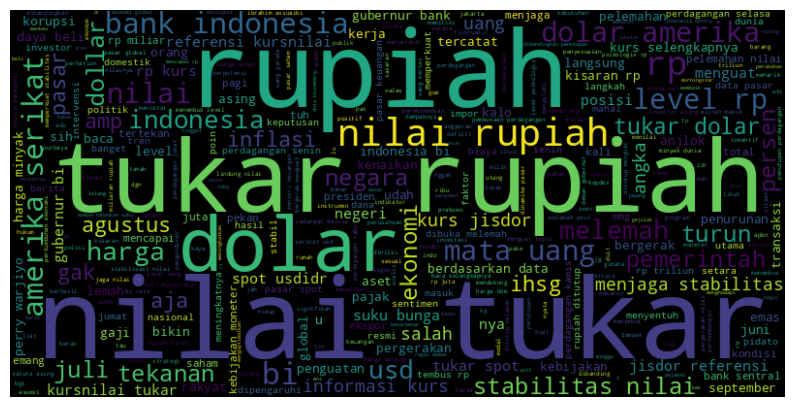

In [18]:
# 1. Word Cloud
# Gabungkan teks dari kolom 'full_text'
data_text = ' '.join(data['full_text'].astype(str).tolist())

# Generate WordCloud
wc = WordCloud(stopwords=stopwords, background_color='black', max_words=500, width=800, height=400).generate(data_text)

# Tampilkan WordCloud menggunakan matplotlib
plt.figure(figsize=(10, 10))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off') # Sembunyikan axis
plt.show()

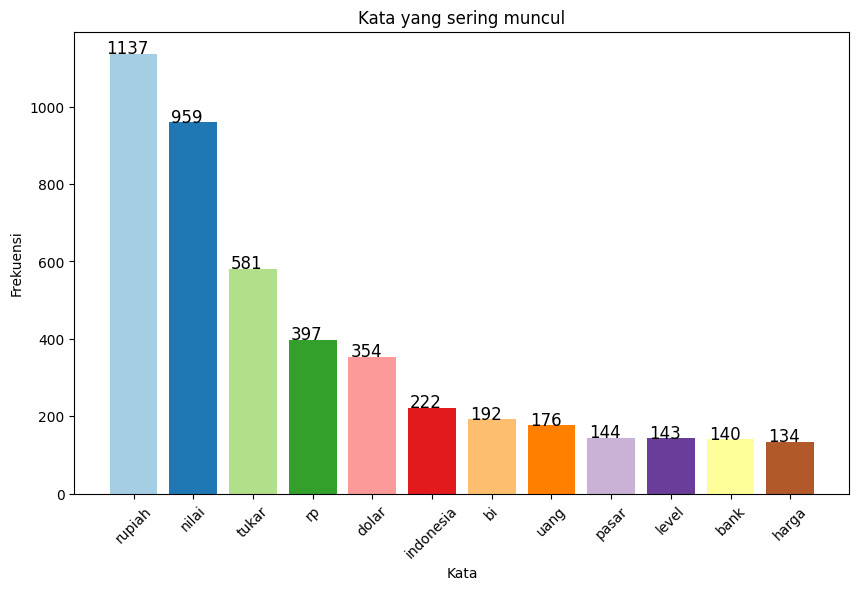

In [19]:
# 2. Bar Chart Kata yang Paling Sering Muncul
# Gabungkan semua teks dari kolom 'full_text'
text = ' '.join(data['full_text'].astype(str).tolist())
words = text.split()
words = [word for word in words if word not in stopwords]

# Hitung frekuensi kata
word_counts = Counter(words)

# Ambil 12 kata yang paling sering muncul
top_words = word_counts.most_common(12)

words, counts = zip(*top_words)

# Buat bar chart menggunakan matplotlib
colors = plt.cm.Paired(range(len(words)))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(words, counts, color=colors)

ax.set_xlabel('Kata')
ax.set_ylabel('Frekuensi')
ax.set_title('Kata yang sering muncul')
ax.set_xticks(range(len(words)))
ax.set_xticklabels(words, rotation=45)

# Tambahkan label frekuensi di atas setiap bar
for bar, num in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2 - 0.1, num + 1, str(num), fontsize=12, color='black', ha='center')

# Tampilkan bar chart
plt.show()